<h2 align="center">MAESTRÍA EN INVESTIGACIÓN EN CIENCIA DE DATOS<br>
FACULTAD DE CIENCIAS FÍSICO MATEMÁTICAS</h2>
<h3 align="center">EXAMEN I</h3>

<div style="text-align:justify">
<b>IMPORTANTE</b><br>
* El examen tendrá como aspectos a evaluar la funcionalidad de código (80%) y la calidad del código realizado (20%).</div>

Alumno: Edilberto Antonio Gómez García.

> 1.- Using the "newsapi-python", extract the content of newspaper´s articles with the keywords "Trump" and "Zelenskyy" in "BBC-News"(initial date: 2024-08-29, end date: 2024-09-26). Compare the first words which are available in the content section and 1) compare the articles using cosine similarity function (all the combinations).2) Determine the distance between the documents using the cosine distance.

In [14]:
#Use this example:
!python -m pip install newsapi-python   #installing newsapi-python
from newsapi import NewsApiClient
api = NewsApiClient(api_key='74f447e0ec1248eb82b043340ff02034')  #to obtain your api key, sign up in https://newsapi.org/register
all_articles=api.get_everything(q='Zelenskyy OR Trump',sources="bbc-news",from_param='2026-09-05',to='2026-09-30',language='en',sort_by='relevancy')
#all_articles["articles"]   #This is a list containing the articles. From this list you have to extract the articles´s content.

In [16]:
def limpieza(texto:str) -> str:
    texto = texto.lower().replace('.', ' ').replace(":"," ").replace(","," ").replace('\\',"")
    return texto

In [98]:
type(all_articles['articles'])
content_articles = {limpieza(articulos['title']): limpieza(articulos['content'][:150]) for articulos in all_articles['articles']}


In [109]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

conteo = {}
for titulo, contenido in content_articles.items():
    palabras = contenido.split()
    conteo_palabras = {}
    for palabra in palabras:
        if palabra in conteo_palabras:
            conteo_palabras[palabra] += 1
        else:
            conteo_palabras[palabra] = 1
    conteo[titulo] = conteo_palabras

conteo_palabras_articulos = pd.DataFrame(conteo)
conteo_palabras_articulos = conteo_palabras_articulos.fillna(0)
conteo_palabras_articulos = conteo_palabras_articulos.astype(int)

matriz_articulos = conteo_palabras_articulos.T

similaridad_coseno = cosine_similarity(matriz_articulos)
distancia_coseno = 1 - similaridad_coseno

titulos_articulos = matriz_articulos.index

resultados = []
n = len(titulos_articulos)
for i in range(n):
    for j in range(i + 1, n):
        resultados.append({
            'Artículo 1': titulos_articulos[i],
            'Artículo 2': titulos_articulos[j],
            'Similitud Coseno': similaridad_coseno[i, j],
            'Distancia Coseno': distancia_coseno[i, j]
        })

resultados = pd.DataFrame(resultados)
resultados

,Artículo 1,Artículo 2,Similitud Coseno,Distancia Coseno
0,trump signs sweeping russia sanctions bill,donald trump jr and bettina trump say putin al...,0.259973,0.740027
1,trump signs sweeping russia sanctions bill,trump says his planned triumphal arch will dou...,0.269430,0.730570
2,trump signs sweeping russia sanctions bill,manchester to host world leaders at g20 summit...,0.156893,0.843107
3,trump signs sweeping russia sanctions bill,trump shares misleading video of king and fain...,0.297113,0.702887
4,trump signs sweeping russia sanctions bill,why trump is all-in on ai despite the warnings,0.115470,0.884530
...,...,...,...,...
4945,trump says ai safety fears a 'hoax' as he reje...,premier league joins call for fifa reforms,0.262613,0.737387
4946,trump says ai safety fears a 'hoax' as he reje...,openai gives cyber defence tools to ukraine,0.345271,0.654729
4947,us criticises australia's proposed algorithm o...,premier league joins call for fifa reforms,0.268926,0.731074
4948,us criticises australia's proposed algorithm o...,openai gives cyber defence tools to ukraine,0.228571,0.771429


> 2.-  Download PM10 data for Agua Santa (see the attached file) and perform the following tasks: 1) Normalize the dataset, 2) standarize the PM10 data, 3) Determine the number of outliers using IQR criteria, 4) Determine the number of missing values.

In [113]:
sinaica = pd.read_excel('Datos SINAICA.xlsx')
#sinaica.dropna(inplace=True)
sinaica.head()

,Par噈etro,Fecha,Hora,Concentraciones horarias,Unidad
0,NaN,NaT,NaN,NaN,NaN
1,PM10,2025-08-01,23:00 - 0:00,27.0,礸/m_
2,PM10,2025-08-01,0:00 - 1:00,34.0,礸/m_
3,PM10,2025-08-01,1:00 - 2:00,5.0,礸/m_
4,PM10,2025-08-01,2:00 - 3:00,-7.0,礸/m_


In [114]:
len(sinaica)

8753

In [115]:
sinaica.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8753 entries, 0 to 8752
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Par噈etro                  8752 non-null   object        
 1   Fecha                     8752 non-null   datetime64[ns]
 2   Hora                      8752 non-null   object        
 3   Concentraciones horarias  8752 non-null   float64       
 4   Unidad                    8752 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 342.0+ KB


In [116]:
sinaica.dropna(inplace=True)
len(sinaica)

8752

In [117]:
sinaica['Fecha'] = pd.to_datetime(sinaica['Fecha'], errors='coerce')

In [118]:
sinaica['hora_numero'] = sinaica['Hora'].apply(lambda x: x.split(':')[0])
sinaica.head()

,Par噈etro,Fecha,Hora,Concentraciones horarias,Unidad,hora_numero
1,PM10,2025-08-01,23:00 - 0:00,27.0,礸/m_,23
2,PM10,2025-08-01,0:00 - 1:00,34.0,礸/m_,0
3,PM10,2025-08-01,1:00 - 2:00,5.0,礸/m_,1
4,PM10,2025-08-01,2:00 - 3:00,-7.0,礸/m_,2
5,PM10,2025-08-01,3:00 - 4:00,20.0,礸/m_,3


In [119]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
sinaica['estandarizado'] = scaler.fit_transform(sinaica[['Concentraciones horarias']])
sinaica.head()

,Par噈etro,Fecha,Hora,Concentraciones horarias,Unidad,hora_numero,estandarizado
1,PM10,2025-08-01,23:00 - 0:00,27.0,礸/m_,23,-0.357500
2,PM10,2025-08-01,0:00 - 1:00,34.0,礸/m_,0,-0.121521
3,PM10,2025-08-01,1:00 - 2:00,5.0,礸/m_,1,-1.099147
4,PM10,2025-08-01,2:00 - 3:00,-7.0,礸/m_,2,-1.503682
5,PM10,2025-08-01,3:00 - 4:00,20.0,礸/m_,3,-0.593479


In [122]:
lim_sup = np.quantile(sinaica['estandarizado'], 0.75) + 1.5 * np.std(sinaica['estandarizado'])
lim_inf = np.quantile(sinaica['estandarizado'], 0.25) - 1.5 * np.std(sinaica['estandarizado'])

sinaica['is_outlier'] = np.where(((sinaica['estandarizado'] > lim_sup) | (sinaica['estandarizado'] < lim_inf)), 1, 0)
print(f"The number of outliers is: {sinaica['is_outlier'].sum()}")

The number of outliers is: 322


In [126]:
sum_nan = sinaica['Concentraciones horarias'].isna().sum()
print(f'The number of nan in Concentraciones Horarias is {sum_nan}')

The number of nan in Concentraciones Horarias is 0


Cuando realice la linea sinaica.dropna(inplace=True), sólo eliminé el primer registro, ya que vemos
ese está completamente vacio, más no otros registros, eso lo podemos observar al momento de que
se obtuvo el primer len() que era de 8753 y al ejecutar .dropna() y obtener el len() nuevamente bajo sólo uno
que fue de 8752, correspondiente al primer registro.

> 3.- Retrieve daily financial data for APPLE ("AAPL") using the yfinance library, (you may install it if necessary: https://zoo.cs.yale.edu/classes/cs458/lectures/yfinance.html). Use the period from January 1, 2024, up to January 1, 2025, and analyze the closing-price time series. Apply temporal binning using the mean closing price within each bin, and perform downsampling. Choose appropriate intervals and justify your choices. Display clearly labeled plots of: (a) the original daily closing prices, (b) the series smoothed through bin averaging, and (c) the downsampled series.

In [77]:
!pip install yfinance
import yfinance as yf
import matplotlib.pyplot as plt

In [123]:
empresa = "AAPL"
inicio = "2024-01-01"
fin = "2025-01-01"

apple = yf.download(empresa, start=inicio, end=fin)
precios_cierre = apple['Close']
precios_cierre

/tmp/ipykernel_735/2827083842.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  apple = yf.download(empresa, start=inicio, end=fin)
[*********************100%***********************]  1 of 1 completed


Ticker,AAPL
Date,
2024-01-02,183.404007
2024-01-03,182.030777
2024-01-04,179.718948
2024-01-05,178.997726
2024-01-08,183.324982
...,...
2024-12-24,256.339722
2024-12-26,257.153809
2024-12-27,253.748535


In [124]:
precios_cierre_bin = precios_cierre.rolling(window=3, center=True).mean()
precios_cierre_bin.head()

Ticker,AAPL
Date,
2024-01-02,NaN
2024-01-03,181.717911
2024-01-04,180.249151
2024-01-05,180.680552
2024-01-08,181.744258


Para el bin, elegí una ventana de 3 días, ya que de esta manera, podremos suavizar los datos de ese día, con el promedio que sucedio un día antes y un día después, de esta manera podremos obtener un suavizado, sin perder tantos datos, ya que sólo se pierde el primer y último dato, ya que como estos no pueden tener una ventana completa de 3 días, pues no se calculan.


In [125]:
precios_cierre_downsampling = precios_cierre.resample('W').mean()
precios_cierre_downsampling.head()

Ticker,AAPL
Date,
2024-01-07,181.037865
2024-01-14,183.443527
2024-01-21,184.377163
2024-01-28,191.694940
2024-02-04,185.119095


In [94]:
len(precios_cierre_downsampling)

53

Realicé un downsampling sólo tomando el promedio de cada semana, así, que sólo nos quedará un dato por semana, que será el promedio de esa semana, y yo lo considero un rango justo, ya que tomar un promedio de un mes, será perder muchos datos, y sólo quedarnos con 12, al menos de esta forma seguimos conservando 53 datos

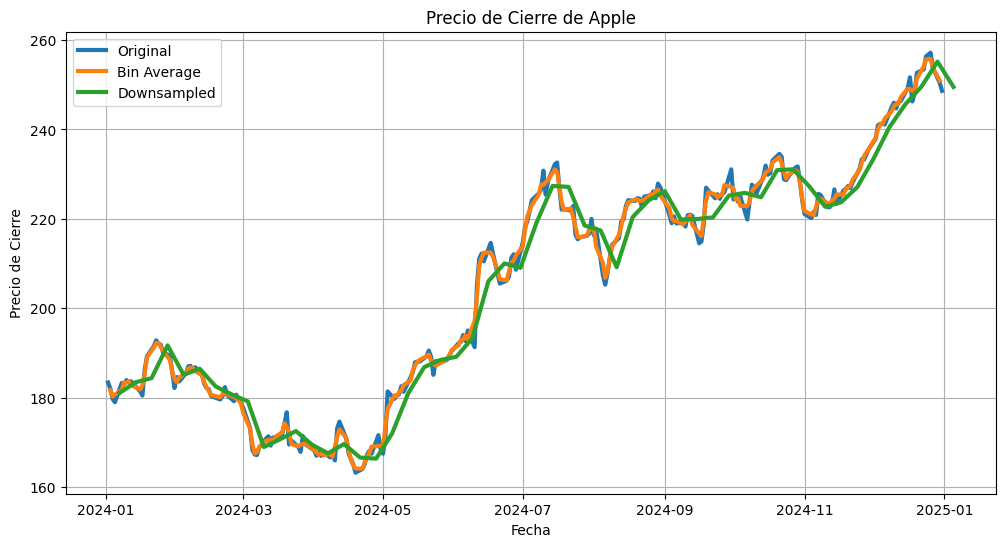

In [93]:
fig = plt.figure(figsize=(12, 6))
plt.plot(precios_cierre, label='Original', lw = 3)
plt.plot(precios_cierre_bin, label='Bin Average', lw = 3)
plt.plot(precios_cierre_downsampling, label='Downsampled', lw= 3)
plt.title('Precio de Cierre de Apple')
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre')
plt.legend()
plt.grid()